# 02 - Baseline: Regressão Logística + TF-IDF

Este notebook treina a baseline clássica do projeto.

**Fluxo metodológico:**
1. Carregamento dos dados (já limpos pelo `preprocessing.py`).
2. Treinamento do TF-IDF e do modelo no conjunto de Treino.
3. Otimização de hiperparâmetros (`GridSearchCV`) usando o conjunto de **Validação**.
4. Avaliação final (métricas e Matriz de Confusão) no conjunto de **Teste**.

## 1. Setup e Carregamento

In [1]:
import sys
import os
import glob
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_from_disk
from IPython.display import display

# --- CORREÇÃO DEFINITIVA DO PATH ---
arquivos_utils = glob.glob("/content/**/src/utils.py", recursive=True)
if arquivos_utils:
    caminho_utils = Path(arquivos_utils[0])
    caminho_src = caminho_utils.parent
    raiz_projeto = caminho_src.parent
    if str(caminho_src) not in sys.path:
        sys.path.insert(0, str(caminho_src))
    print(f"✅ Ambiente configurado. Raiz: {raiz_projeto}")
else:
    raise FileNotFoundError("Não foi possível encontrar o src/utils.py")

from utils import setup_logging, ensure_dir, save_results, compute_metrics, format_metrics

sns.set_theme(style="whitegrid", palette="muted")
logger = setup_logging(name="baseline_rl")

✅ Ambiente configurado. Raiz: /content/Classifica-o-de-Discurso-T-xico-em-Redes-Sociais


In [2]:
# Carrega o dataset limpo
dataset_path = raiz_projeto / "data" / "processed" / "told-br-binary-clean"
ds = load_from_disk(str(dataset_path))

# Convertendo para pandas
df_train = ds['train'].to_pandas()
df_val = ds['validation'].to_pandas()
df_test = ds['test'].to_pandas()

# Extraindo textos e rótulos (usando a coluna limpa gerada pelo preprocessing)
X_train_text = df_train['text_tfidf'].tolist()
y_train = df_train['label'].tolist()

X_val_text = df_val['text_tfidf'].tolist()
y_val = df_val['label'].tolist()

X_test_text = df_test['text_tfidf'].tolist()
y_test = df_test['label'].tolist()

print(f"Treino: {len(X_train_text)} | Validação: {len(X_val_text)} | Teste: {len(X_test_text)}")

Treino: 16800 | Validação: 2100 | Teste: 2100


## 2. Vetorização (TF-IDF)

Vamos criar o vetorizador. Importante: o `fit` (aprender o vocabulário) deve ser feito **apenas no treino**, para não vazar informação da validação/teste.

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Instanciando o TF-IDF
vectorizer = TfidfVectorizer(
    max_features=10000, # Limita o vocabulário às 10.000 palavras mais importantes
    ngram_range=(1, 2)  # Pega palavras únicas e pares de palavras (ex: "muito idiota")
)

# Fit apenas no treino e transform em todos
X_train_tfidf = vectorizer.fit_transform(X_train_text)
X_val_tfidf = vectorizer.transform(X_val_text)
X_test_tfidf = vectorizer.transform(X_test_text)

print(f"Formato da matriz TF-IDF de Treino: {X_train_tfidf.shape}")

Formato da matriz TF-IDF de Treino: (16800, 10000)


## 3. GridSearchCV (Otimização)

Vamos testar várias combinações de hiperparâmetros da Regressão Logística. O GridSearch vai treinar e validar internamente usando validação cruzada (5-fold) **apenas no conjunto de Treino**.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
import time

# Definindo o modelo base
base_model = LogisticRegression(random_state=42, max_iter=1000)

# Definindo a grade de hiperparâmetros para testar
param_grid = {
    'C': [0.1, 1.0, 10.0],          # Força da regularização (menor = mais regularizado)
    'solver': ['liblinear', 'lbfgs'], # Algoritmos de otimização
    'class_weight': [None, 'balanced'] # Lida com o desbalanceamento de classes
}

# Configurando o GridSearch
grid_search = GridSearchCV(
    estimator=base_model,
    param_grid=param_grid,
    cv=5,              # 5-fold cross-validation no treino
    scoring='f1',      # Otimizar para o F1-Score da classe tóxica
    n_jobs=-1,         # Usar todos os núcleos do processador
    verbose=1
)

print("Iniciando GridSearch (isso pode levar alguns minutos)...")
inicio = time.time()
grid_search.fit(X_train_tfidf, y_train)
fim = time.time()

print(f"\nGridSearch concluído em {(fim - inicio)/60:.2f} minutos.")
print(f"Melhores parâmetros encontrados: {grid_search.best_params_}")
print(f"Melhor F1-Score (validação cruzada no treino): {grid_search.best_score_:.4f}")

Iniciando GridSearch (isso pode levar alguns minutos)...
Fitting 5 folds for each of 12 candidates, totalling 60 fits

GridSearch concluído em 0.12 minutos.
Melhores parâmetros encontrados: {'C': 1.0, 'class_weight': 'balanced', 'solver': 'lbfgs'}
Melhor F1-Score (validação cruzada no treino): 0.6996


## 4. Avaliação Final no Conjunto de Teste

Agora pegamos o melhor modelo encontrado e testamos nos dados que ele nunca viu (o `X_test_tfidf`).

In [5]:
# Recuperando o melhor modelo
best_model = grid_search.best_estimator_

# Fazendo as predições no teste
y_pred = best_model.predict(X_test_tfidf)
y_proba = best_model.predict_proba(X_test_tfidf)

# Calculando as métricas usando a nossa função do utils.py
metrics = compute_metrics(y_test, y_pred, y_proba, average='binary')

print("=" * 60)
print("RESULTADOS DA REGRESSÃO LOGÍSTICA NO TESTE")
print("=" * 60)
print(format_metrics(metrics))
print("=" * 60)

# Salvando resultados para o evaluate.py posteriormente
resultados_rl = {
    "modelo": "Regressão Logística",
    "melhores_parametros": grid_search.best_params_,
    "metricas_teste": metrics
}
ensure_dir(raiz_projeto / 'results' / 'metrics')
save_results(resultados_rl, raiz_projeto / 'results' / 'metrics', filename="baseline_rl_metrics.json")

RESULTADOS DA REGRESSÃO LOGÍSTICA NO TESTE
          f1: 0.7018
   precision: 0.7051
      recall: 0.6986
    accuracy: 0.7252
         auc: 0.8108


PosixPath('/content/Classifica-o-de-Discurso-T-xico-em-Redes-Sociais/results/metrics/baseline_rl_metrics.json')

## 5. Matriz de Confusão

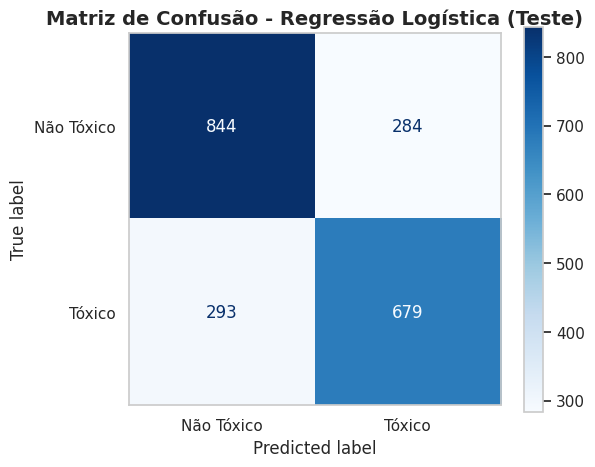

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculando a matriz
cm = confusion_matrix(y_test, y_pred)

# Plotando
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Não Tóxico', 'Tóxico'])
disp.plot(cmap='Blues', ax=ax, values_format='d')

plt.title('Matriz de Confusão - Regressão Logística (Teste)', fontsize=14, fontweight='bold')
plt.grid(False)

# Salvando a figura
ensure_dir(raiz_projeto / 'results' / 'figures')
fig_path = raiz_projeto / 'results' / 'figures' / '02_matriz_confusao_rl.png'
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

## 6. Download dos Resultados
Como não usamos Google Drive, baixamos os artefatos gerados.

In [7]:
import shutil
from google.colab import files

# Compacta as figuras
archive_path = shutil.make_archive("/content/resultados_rl", "zip", str(raiz_projeto / 'results' / 'figures'))
print(f"Baixando: {archive_path}")
files.download(archive_path)

Baixando: /content/resultados_rl.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>